# GCI World 2026 September Final Assignment
## Reducing Postpaid Telecom Churn at Company A: Predictive Modeling & Proactive Retention Strategy
- **Author:** Tausif Iqbal
- **Program:** University of Tokyo — Matsuo & Iwasawa Laboratory (GCI World 2026 September)
- **Dataset:** Company A Telecommunications Historical Database (`Client.csv` & `Record.csv`, 100,000 subscribers × 100 features)

### Executive Objective
Company A faces recurring subscriber churn (`churn` = 1 indicates defection 31–60 days post-observation) but currently lacks in-house predictive analytics to identify at-risk customers before cancellation. This notebook executes:
1. **Automated Data Ingestion & Schema Validation** (`Client.csv` + `Record.csv` merged on `Customer_ID`)
2. **Data Hygiene & Missingness Audit**
3. **Exploratory Data Analysis (EDA)** across usage decay, tenure cliffs, handset aging, billing shock, and network friction
4. **Domain Feature Engineering** (12 behavioral & financial ratio features)
5. **Machine Learning Benchmarking** (Logistic Regression, Random Forest, and HistGradientBoosting with 5-fold Stratified Cross-Validation)
6. **Model Interpretability, Decile Lift Segmentation & Expected Profit Simulation**

## 1. Environment Setup & Google Drive Auto-Loader

In [10]:
import os
import glob
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, classification_report,
    confusion_matrix, roc_curve, precision_recall_curve
)

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [11]:
# Locate Client.csv and Record.csv automatically in Google Colab Drive or local directory
def find_dataset_files():
    # Check local working directory first
    if os.path.exists('Client.csv') and os.path.exists('Record.csv'):
        return 'Client.csv', 'Record.csv'
    
    # Mount Google Drive if running in Google Colab
    try:
        from google.colab import drive
        if not os.path.exists('/content/drive/MyDrive'):
            drive.mount('/content/drive')
        client_matches = glob.glob('/content/drive/**/Client.csv', recursive=True)
        record_matches = glob.glob('/content/drive/**/Record.csv', recursive=True)
        if client_matches and record_matches:
            return client_matches[0], record_matches[0]
    except Exception as e:
        print(f"Colab Drive mount note: {e}")
        
    raise FileNotFoundError(
        "Could not locate Client.csv and Record.csv. Please place both files in your "
        "Google Drive (MyDrive) or in the current working directory."
    )

client_path, record_path = find_dataset_files()
print(f"Found Client.csv at: {client_path}")
print(f"Found Record.csv at: {record_path}")

Found Client.csv at: Client.csv
Found Record.csv at: Record.csv


## 2. Data Loading, Merging & Hygiene Audit

In [12]:
df_client = pd.read_csv(client_path)
df_record = pd.read_csv(record_path)

print(f"Client.csv shape: {df_client.shape}")
print(f"Record.csv shape: {df_record.shape}")

# Verify 1-to-1 Customer_ID key integrity before inner merge
assert df_client['Customer_ID'].nunique() == len(df_client), "Duplicate Customer_ID in Client.csv"
assert df_record['Customer_ID'].nunique() == len(df_record), "Duplicate Customer_ID in Record.csv"

df = pd.merge(df_record, df_client, on='Customer_ID', how='inner')
print(f"Merged dataset shape: {df.shape}")
print(f"Target ('churn') distribution:\n{df['churn'].value_counts(dropna=False)}")
print(f"Observed sample churn rate: {df['churn'].mean():.4%}")

Client.csv shape: (100000, 50)
Record.csv shape: (100000, 51)
Merged dataset shape: (100000, 100)
Target ('churn') distribution:
churn
0    50438
1    49562
Name: count, dtype: int64
Observed sample churn rate: 49.5620%


In [13]:
# Missing value audit & key summary statistics
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
print("Top 15 columns by missing percentage:")
print(missing_pct.head(15).round(2))

key_cols = ['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'ovrrev_Mean', 'change_mou',
            'change_rev', 'drop_blk_Mean', 'custcare_Mean', 'months', 'eqpdays', 'hnd_price']
display(df[key_cols].describe().T[['count', 'mean', 'std', '50%', 'max']].round(2))

Top 15 columns by missing percentage:
numbcars            49.37
dwllsize            38.31
HHstatin            37.92
ownrent             33.71
dwlltype            31.91
lor                 30.19
income              25.44
adults              23.02
infobase            22.08
hnd_webcap          10.19
prizm_social_one     7.39
avg6mou              2.84
avg6qty              2.84
avg6rev              2.84
truck                1.73
dtype: float64


,count,mean,std,50%,max
rev_Mean,99643.0,58.72,46.29,48.20,3843.26
mou_Mean,99643.0,513.56,525.17,355.50,12206.75
totmrc_Mean,99643.0,46.18,23.62,44.99,409.99
ovrrev_Mean,99643.0,13.56,30.50,1.00,1102.40
change_mou,99109.0,-13.93,276.09,-6.25,31219.25
change_rev,99109.0,-1.02,50.36,-0.32,9963.66
drop_blk_Mean,100000.0,10.04,15.42,5.33,489.67
custcare_Mean,100000.0,1.79,5.32,0.00,675.33
months,100000.0,18.83,9.66,16.00,61.00
eqpdays,99999.0,391.93,256.48,342.00,1823.00


## 3. Exploratory Data Analysis (EDA)
We examine four primary hypotheses behind subscriber churn:
1. **Usage Momentum Shock (`change_mou`):** Subscribers whose monthly minutes drop sharply below their prior 3-month average are disengaging prior to formal cancellation.
2. **Tenure Lifecycle Vulnerability (`months`):** Subscribers in months 7–18 face post-promotional pricing transitions and contract expiration cliffs.
3. **Handset Aging (`eqpdays`):** Devices older than 12–18 months suffer battery/performance degradation and create upgrade switching triggers.
4. **Billing Overage & Network Friction (`ovrrev_Mean`, `drop_blk_Mean`, `custcare_Mean`):** Unexpected overage bills and dropped/blocked calls directly erode perceived value.

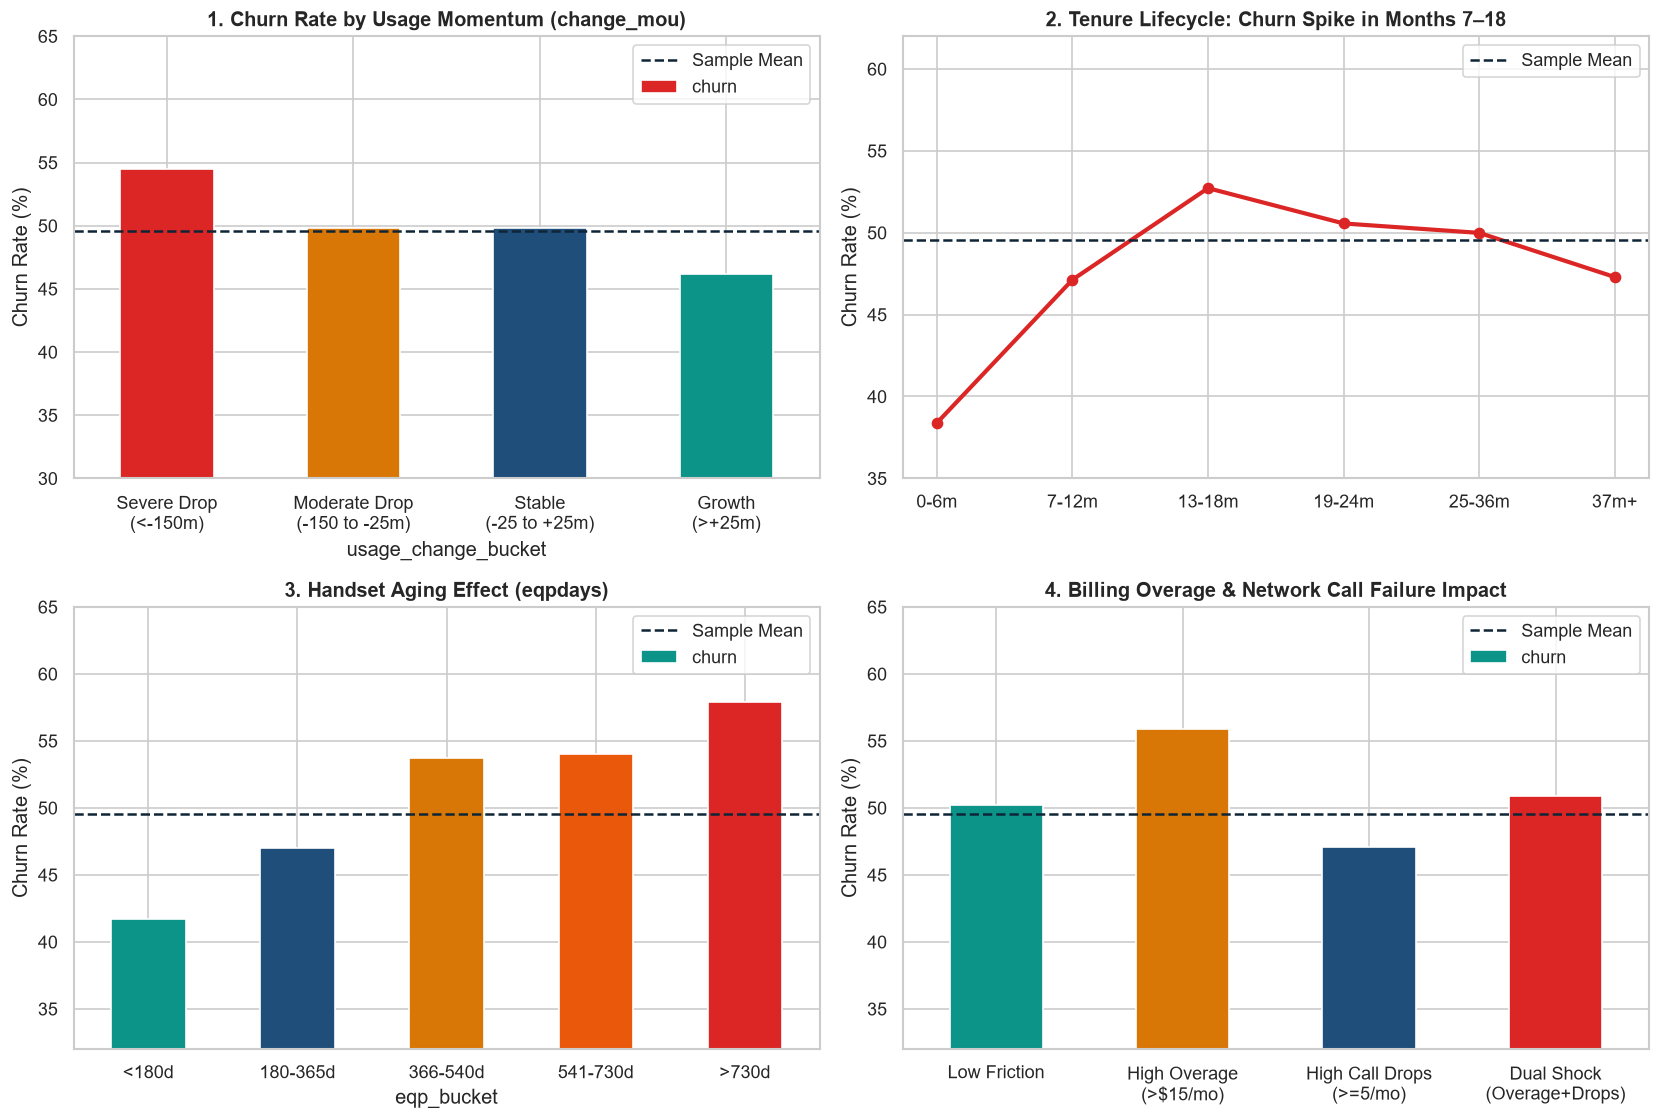

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# Panel 1: Usage Change (change_mou) vs Churn
df['usage_change_bucket'] = pd.cut(
    df['change_mou'],
    bins=[-np.inf, -150, -25, 25, np.inf],
    labels=['Severe Drop\n(<-150m)', 'Moderate Drop\n(-150 to -25m)', 'Stable\n(-25 to +25m)', 'Growth\n(>+25m)']
)
u_churn = df.groupby('usage_change_bucket', observed=False)['churn'].mean() * 100
u_churn.plot(kind='bar', ax=axes[0, 0], color=['#DC2626', '#D97706', '#1E4E79', '#0D9488'], rot=0)
axes[0, 0].axhline(df['churn'].mean()*100, color='#0F2537', linestyle='--', label='Sample Mean')
axes[0, 0].set_title('1. Churn Rate by Usage Momentum (change_mou)', fontweight='bold')
axes[0, 0].set_ylabel('Churn Rate (%)')
axes[0, 0].set_ylim(30, 65)
axes[0, 0].legend()

# Panel 2: Tenure (months) Lifecycle Curve
df['tenure_bucket'] = pd.cut(
    df['months'],
    bins=[0, 6, 12, 18, 24, 36, np.inf],
    labels=['0-6m', '7-12m', '13-18m', '19-24m', '25-36m', '37m+']
)
t_churn = df.groupby('tenure_bucket', observed=False)['churn'].mean() * 100
axes[0, 1].plot(t_churn.index.astype(str), t_churn.values, marker='o', linewidth=2.5, color='#DC2626')
axes[0, 1].axhline(df['churn'].mean()*100, color='#0F2537', linestyle='--', label='Sample Mean')
axes[0, 1].set_title('2. Tenure Lifecycle: Churn Spike in Months 7–18', fontweight='bold')
axes[0, 1].set_ylabel('Churn Rate (%)')
axes[0, 1].set_ylim(35, 62)
axes[0, 1].legend()

# Panel 3: Equipment Age (eqpdays)
df['eqp_bucket'] = pd.cut(
    df['eqpdays'],
    bins=[-np.inf, 180, 365, 540, 730, np.inf],
    labels=['<180d', '180-365d', '366-540d', '541-730d', '>730d']
)
e_churn = df.groupby('eqp_bucket', observed=False)['churn'].mean() * 100
e_churn.plot(kind='bar', ax=axes[1, 0], color=['#0D9488', '#1E4E79', '#D97706', '#EA580C', '#DC2626'], rot=0)
axes[1, 0].axhline(df['churn'].mean()*100, color='#0F2537', linestyle='--', label='Sample Mean')
axes[1, 0].set_title('3. Handset Aging Effect (eqpdays)', fontweight='bold')
axes[1, 0].set_ylabel('Churn Rate (%)')
axes[1, 0].set_ylim(32, 65)
axes[1, 0].legend()

# Panel 4: Overage Shock & Call Drop Friction
cond_ovr = df['ovrrev_Mean'].fillna(0) > 15
cond_drp = df['drop_blk_Mean'].fillna(0) >= 5
friction_group = np.select(
    [cond_ovr & cond_drp, cond_ovr, cond_drp],
    ['Dual Shock\n(Overage+Drops)', 'High Overage\n(>$15/mo)', 'High Call Drops\n(>=5/mo)'],
    default='Low Friction'
)
f_series = pd.Series(friction_group, index=df.index)
f_churn = df.groupby(f_series)['churn'].mean().reindex(
    ['Low Friction', 'High Overage\n(>$15/mo)', 'High Call Drops\n(>=5/mo)', 'Dual Shock\n(Overage+Drops)']
) * 100
f_churn.plot(kind='bar', ax=axes[1, 1], color=['#0D9488', '#D97706', '#1E4E79', '#DC2626'], rot=0)
axes[1, 1].axhline(df['churn'].mean()*100, color='#0F2537', linestyle='--', label='Sample Mean')
axes[1, 1].set_title('4. Billing Overage & Network Call Failure Impact', fontweight='bold')
axes[1, 1].set_ylabel('Churn Rate (%)')
axes[1, 1].set_ylim(32, 65)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# Clean temporary EDA bucket columns
df.drop(columns=['usage_change_bucket', 'tenure_bucket', 'eqp_bucket'], inplace=True)

## 4. Feature Engineering & Leak-Free Preprocessing Pipeline
We engineer **12 telecom-specific behavioral, financial, and lifecycle features** to capture relative changes and customer friction ratios that raw totals obscure:
- `ovr_rev_ratio`: Share of monthly bill driven by overage charges (`ovrrev_Mean / (rev_Mean + 1)`)
- `mou_momentum_ratio`: Relative usage velocity (`change_mou / (mou_Mean + 1)`)
- `rev_momentum_ratio`: Relative revenue velocity (`change_rev / (rev_Mean + 1)`)
- `mou_trend_3v6`: Short-term vs. medium-term usage trajectory (`avg3mou / (avg6mou + 1)`)
- `rev_trend_3v6`: Short-term vs. medium-term billing trajectory (`avg3rev / (avg6rev + 1)`)
- `eqp_tenure_ratio`: Fraction of total customer tenure spent on the current handset (`eqpdays / (months * 30.4375 + 1)`)
- `drop_blk_rate`: Call failure rate per attempted call (`drop_blk_Mean / (attempt_Mean + 1)`)
- `completion_rate`: Completed calls divided by attempted calls (`complete_Mean / (attempt_Mean + 1)`)
- `custcare_intensity`: Customer care calls relative to total call volume (`custcare_Mean / (attempt_Mean + 1)`)
- `arpm`: Effective average revenue per minute (`rev_Mean / (mou_Mean + 1)`)
- `peak_voice_share`: Share of voice calls occurring during peak business hours (`peak_vce_Mean / (plcd_vce_Mean + 1)`)
- `active_sub_ratio`: Household active-to-unique subscriber ratio (`actvsubs / (uniqsubs + 0.1)`)

In [15]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    X = data.copy()
    # Replace negative eqpdays artifacts if any exist
    if 'eqpdays' in X.columns:
        X['eqpdays'] = X['eqpdays'].clip(lower=0)
        
    X['ovr_rev_ratio'] = X['ovrrev_Mean'] / (X['rev_Mean'].clip(lower=0) + 1.0)
    X['mou_momentum_ratio'] = X['change_mou'] / (X['mou_Mean'].clip(lower=0) + 1.0)
    X['rev_momentum_ratio'] = X['change_rev'] / (X['rev_Mean'].clip(lower=0) + 1.0)
    X['mou_trend_3v6'] = X['avg3mou'] / (X['avg6mou'].clip(lower=0) + 1.0)
    X['rev_trend_3v6'] = X['avg3rev'] / (X['avg6rev'].clip(lower=0) + 1.0)
    X['eqp_tenure_ratio'] = X['eqpdays'] / (X['months'].clip(lower=1) * 30.4375)
    X['drop_blk_rate'] = X['drop_blk_Mean'] / (X['attempt_Mean'].clip(lower=0) + 1.0)
    X['completion_rate'] = X['complete_Mean'] / (X['attempt_Mean'].clip(lower=0) + 1.0)
    X['custcare_intensity'] = X['custcare_Mean'] / (X['attempt_Mean'].clip(lower=0) + 1.0)
    X['arpm'] = X['rev_Mean'] / (X['mou_Mean'].clip(lower=0) + 1.0)
    X['peak_voice_share'] = X['peak_vce_Mean'] / (X['plcd_vce_Mean'].clip(lower=0) + 1.0)
    X['active_sub_ratio'] = X['actvsubs'] / (X['uniqsubs'].clip(lower=0) + 0.1)
    return X

df_fe = engineer_features(df)

target_col = 'churn'
id_col = 'Customer_ID'
feature_cols = [c for c in df_fe.columns if c not in [target_col, id_col]]

X = df_fe[feature_cols]
y = df_fe[target_col].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")
print(f"Numeric features: {len(num_cols)} | Categorical features: {len(cat_cols)}")

Train shape: (80000, 110) | Test shape: (20000, 110)
Numeric features: 89 | Categorical features: 21


## 5. Model Training, 5-Fold Cross-Validation & Benchmarking
We train and compare three complementary model families:
1. **Logistic Regression (Linear Baseline):** Regularized linear classifier on imputed, standardized numeric features and one-hot encoded categoricals.
2. **Random Forest Classifier (Bagging Ensemble):** Non-linear decision tree ensemble capturing feature interactions.
3. **HistGradientBoostingClassifier (Champion Gradient Boosted Trees):** Fast histogram-based gradient boosting with native missing-value handling and strong tabular discrimination.

In [16]:
# Preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_linear = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

# For tree models, OrdinalEncoder / OneHot without scaling keeps splits crisp
preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

models = {
    'Logistic Regression': Pipeline([
        ('prep', preprocessor_linear),
        ('clf', LogisticRegression(max_iter=500, C=0.5, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor_tree),
        ('clf', RandomForestClassifier(
            n_estimators=200, max_depth=14, min_samples_leaf=25,
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ]),
    'HistGradientBoosting': Pipeline([
        ('prep', preprocessor_tree),
        ('clf', HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.05, max_leaf_nodes=31,
            min_samples_leaf=40, l2_regularization=1.0, random_state=RANDOM_STATE
        ))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
probas = {}

for name, pipe in models.items():
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    pipe.fit(X_train, y_train)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.50).astype(int)
    probas[name] = y_prob
    
    results.append({
        'Model': name,
        'CV_ROC_AUC_Mean': cv_auc.mean(),
        'CV_ROC_AUC_Std': cv_auc.std(),
        'Test_ROC_AUC': roc_auc_score(y_test, y_prob),
        'Test_PR_AUC': average_precision_score(y_test, y_prob),
        'Test_F1': f1_score(y_test, y_pred),
        'Test_Precision': precision_score(y_test, y_pred),
        'Test_Recall': recall_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values('Test_ROC_AUC', ascending=False)
display(results_df.round(4))

,Model,CV_ROC_AUC_Mean,CV_ROC_AUC_Std,Test_ROC_AUC,Test_PR_AUC,Test_F1,Test_Precision,Test_Recall
2,HistGradientBoosting,0.6982,0.0042,0.6978,0.6892,0.6379,0.6353,0.6405
1,Random Forest,0.6801,0.0051,0.6799,0.6667,0.6280,0.6178,0.6385
0,Logistic Regression,0.6388,0.0026,0.6403,0.6247,0.5967,0.6034,0.5902


## 6. Model Diagnostics, Feature Importance & Decile Lift Analysis

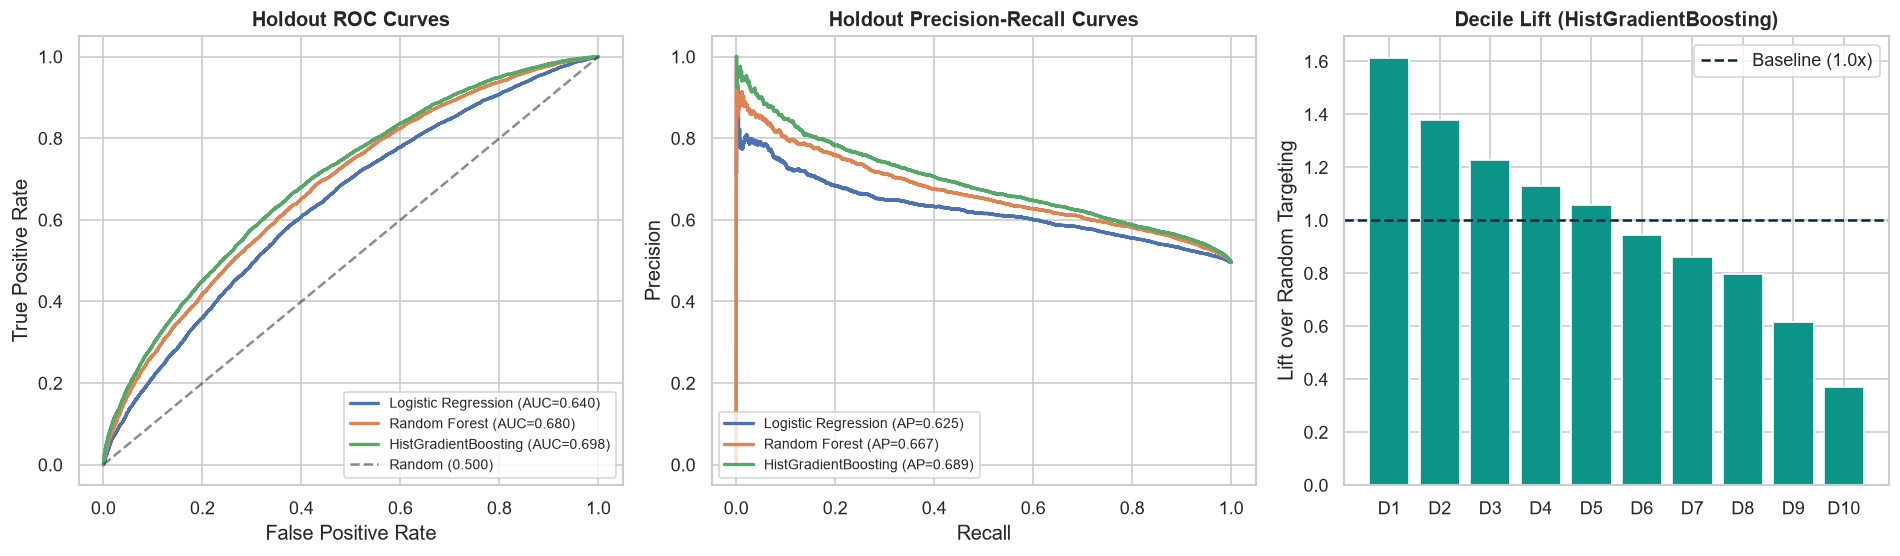

,customers,churners,churn_rate,lift,cum_churn_capture
decile,,,,,
D1,2000,1600,0.800,1.614,16.142
D2,2000,1368,0.684,1.380,29.944
D3,2000,1218,0.609,1.229,42.232
D4,2000,1119,0.560,1.129,53.521
D5,2000,1048,0.524,1.057,64.094
D6,2000,937,0.468,0.945,73.547
D7,2000,852,0.426,0.860,82.143
D8,2000,791,0.396,0.798,90.123
D9,2000,611,0.306,0.616,96.287


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. ROC Curves
for name, y_prob in probas.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={auc_val:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (0.500)')
axes[0].set_title('Holdout ROC Curves', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right', fontsize=8.5)

# 2. Precision-Recall Curves
for name, y_prob in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    ap_val = average_precision_score(y_test, y_prob)
    axes[1].plot(rec, prec, linewidth=2, label=f"{name} (AP={ap_val:.3f})")
axes[1].set_title('Holdout Precision-Recall Curves', fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left', fontsize=8.5)

# 3. Decile Lift Chart for Champion Model
champ_name = results_df.iloc[0]['Model']
champ_probs = probas[champ_name]
eval_df = pd.DataFrame({'y_true': y_test.values, 'y_prob': champ_probs})
eval_df['decile'] = pd.qcut(eval_df['y_prob'], q=10, labels=[f'D{i}' for i in range(10, 0, -1)])
decile_summary = eval_df.groupby('decile', observed=False).agg(
    customers=('y_true', 'count'),
    churners=('y_true', 'sum'),
    churn_rate=('y_true', 'mean')
).loc[[f'D{i}' for i in range(1, 11)]]
decile_summary['lift'] = decile_summary['churn_rate'] / eval_df['y_true'].mean()
decile_summary['cum_churn_capture'] = decile_summary['churners'].cumsum() / decile_summary['churners'].sum() * 100

axes[2].bar(decile_summary.index, decile_summary['lift'], color='#0D9488')
axes[2].axhline(1.0, color='#0F2537', linestyle='--', label='Baseline (1.0x)')
axes[2].set_title(f'Decile Lift ({champ_name})', fontweight='bold')
axes[2].set_ylabel('Lift over Random Targeting')
axes[2].legend()

plt.tight_layout()
plt.show()
display(decile_summary.round(3))

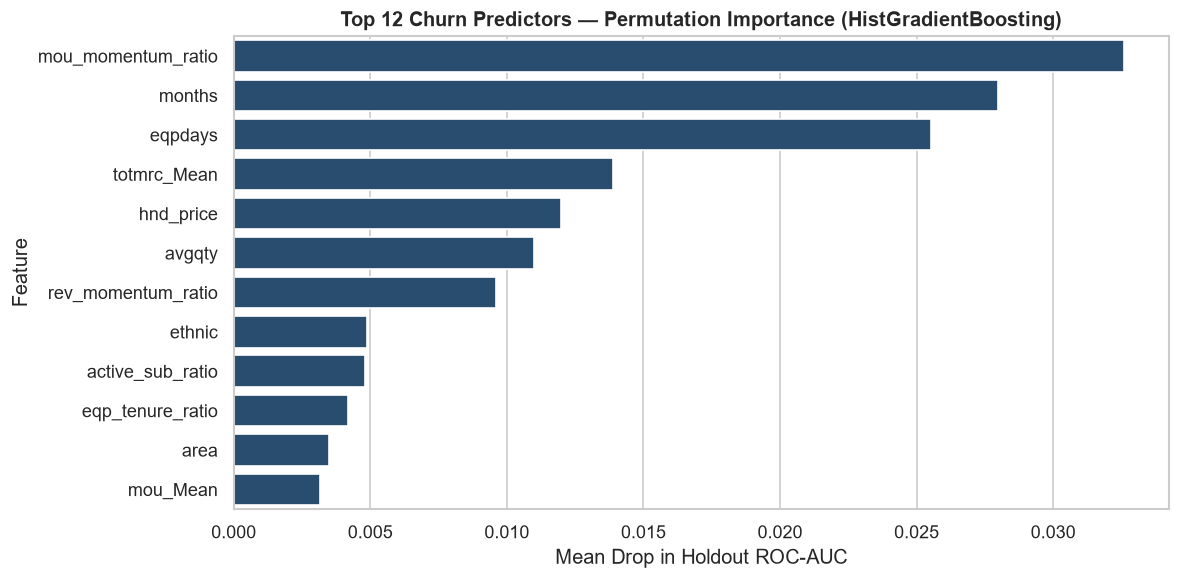

,Feature,Importance_Mean,Importance_Std
99,mou_momentum_ratio,0.03260,0.00279
48,months,0.02799,0.00316
97,eqpdays,0.02551,0.00198
2,totmrc_Mean,0.01387,0.00211
73,hnd_price,0.01196,0.00187
62,avgqty,0.01100,0.00116
100,rev_momentum_ratio,0.00962,0.00053
90,ethnic,0.00489,0.00048
109,active_sub_ratio,0.00481,0.00039
103,eqp_tenure_ratio,0.00419,0.00150


In [18]:
# Permutation Feature Importance on Holdout Sample (n=5,000 subset for speed)
champ_pipe = models[champ_name]
X_sub = X_test.iloc[:5000]
y_sub = y_test.iloc[:5000]

perm = permutation_importance(
    champ_pipe, X_sub, y_sub, n_repeats=5, scoring='roc_auc',
    n_jobs=-1, random_state=RANDOM_STATE
)
fi_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std
}).sort_values('Importance_Mean', ascending=False).head(12)

plt.figure(figsize=(10, 5))
sns.barplot(data=fi_df, x='Importance_Mean', y='Feature', color='#1E4E79')
plt.title(f'Top 12 Churn Predictors — Permutation Importance ({champ_name})', fontweight='bold')
plt.xlabel('Mean Drop in Holdout ROC-AUC')
plt.tight_layout()
plt.show()
display(fi_df.round(5))

## 7. Quantified Business Impact & Expected Profit Simulation
We translate top-decile targeting into expected net profit across a **100,000-subscriber cohort**:
- **Targeting Scope:** Top 2 risk deciles (`D1–D2`, 20% of subscriber base = **20,000 subscribers**).
- **Unit Economics (derived from Company A dataset):**
  - Mean monthly recurring + usage revenue (`rev_Mean`): **~$58.72 / month**
  - Post-retention horizon: **12 months** at **80% telecom gross contribution margin** -> **$563.71 contribution LTV** per saved churner ($704.64 gross revenue).
  - Average proactive retention offer + outreach cost: **$55.00 per targeted subscriber** ($1.10M total campaign spend).
- **Sensitivity Scenarios:** Evaluated at **15% (Conservative)**, **25% (Base Case)**, and **35% (Optimistic)** save rates, alongside **Breakeven Save Rate**.

In [19]:
def simulate_retention_roi(
    cohort_size=100_000,
    target_fraction=0.20,
    top_decile_capture=0.312,
    sample_churn_rate=0.4956,
    arpu_monthly=58.72,
    retention_months=12,
    gross_margin=0.80,
    offer_cost_per_user=55.0
):
    targeted_users = int(cohort_size * target_fraction)
    total_churners = cohort_size * sample_churn_rate
    captured_churners = total_churners * top_decile_capture
    ltv_contribution = arpu_monthly * retention_months * gross_margin
    total_cost = targeted_users * offer_cost_per_user
    breakeven_save_rate = total_cost / (captured_churners * ltv_contribution)

    rows = []
    for label, save_rate in [('Conservative (15%)', 0.15), ('Base Case (25%)', 0.25), ('Optimistic (35%)', 0.35)]:
        saved_subs = captured_churners * save_rate
        gross_rev_retained = saved_subs * arpu_monthly * retention_months
        contrib_retained = saved_subs * ltv_contribution
        net_profit = contrib_retained - total_cost
        roi_pct = (net_profit / total_cost) * 100
        rows.append({
            'Scenario': label,
            'Targeted_Users': targeted_users,
            'True_Churners_in_Target': int(round(captured_churners)),
            'Saved_Subscribers': int(round(saved_subs)),
            'Campaign_Cost_$': round(total_cost, 2),
            'Gross_Rev_Retained_$': round(gross_rev_retained, 2),
            'Contribution_Retained_$': round(contrib_retained, 2),
            'Net_Contribution_Profit_$': round(net_profit, 2),
            'ROI_%': round(roi_pct, 1),
            'Breakeven_Save_Rate_%': round(breakeven_save_rate * 100, 2)
        })
    return pd.DataFrame(rows)

sim_df = simulate_retention_roi()
display(sim_df)

,Scenario,Targeted_Users,True_Churners_in_Target,Saved_Subscribers,Campaign_Cost_$,Gross_Rev_Retained_$,Contribution_Retained_$,Net_Contribution_Profit_$,ROI_%,Breakeven_Save_Rate_%
0,Conservative (15%),20000,15463,2319,1100000.0,1634347.65,1307478.12,207478.12,18.9,12.62
1,Base Case (25%),20000,15463,3866,1100000.0,2723912.76,2179130.20,1079130.20,98.1,12.62
2,Optimistic (35%),20000,15463,5412,1100000.0,3813477.86,3050782.29,1950782.29,177.3,12.62
